In [1]:
# ============================================
# Data Collection
# Imports + Setup
# ============================================

import requests
import pandas as pd
import numpy as np
import os
import time
from datetime import datetime, timedelta
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')

from dotenv import load_dotenv
load_dotenv('../.env', override=True)

WAQI_TOKEN = os.getenv('WAQI_TOKEN')

# Paths
BASE_DIR = Path('../')
RAW_DIR  = BASE_DIR / 'data/raw'
PROC_DIR = BASE_DIR / 'data/processed'

# 5 Cities
CITIES = ['Delhi', 'Mumbai', 'Berlin', 'Geneva', 'Los Angeles']

print("✓ All imports done!")
print(f"✓ Token loaded: {WAQI_TOKEN[:8]}... (hidden)")
print(f"✓ Cities: {CITIES}")

✓ All imports done!
✓ Token loaded: 09372305... (hidden)
✓ Cities: ['Delhi', 'Mumbai', 'Berlin', 'Geneva', 'Los Angeles']


In [2]:
# ============================================
# Historical Data (7 days)
# ============================================

def fetch_historical_waqi(city, token):
    """Fetch last 7 days hourly data for a city"""
    all_records = []
    
    # Last 7 days
    for days_ago in range(7, 0, -1):
        date = (datetime.now() - timedelta(days=days_ago)).strftime('%Y-%m-%d')
        url = f"https://api.waqi.info/feed/{city}/"
        params = {'token': token}
        
        try:
            resp = requests.get(url, params=params, timeout=15)
            data = resp.json()
            
            if data['status'] == 'ok':
                d = data['data']
                iaqi = d.get('iaqi', {})
                
                record = {
                    'city':        city,
                    'date':        date,
                    'aqi':         d.get('aqi', None),
                    'pm25':        iaqi.get('pm25', {}).get('v', None),
                    'pm10':        iaqi.get('pm10', {}).get('v', None),
                    'no2':         iaqi.get('no2',  {}).get('v', None),
                    'o3':          iaqi.get('o3',   {}).get('v', None),
                    'co':          iaqi.get('co',   {}).get('v', None),
                    'so2':         iaqi.get('so2',  {}).get('v', None),
                    'humidity':    iaqi.get('h',    {}).get('v', None),
                    'temperature': iaqi.get('t',    {}).get('v', None),
                    'wind':        iaqi.get('w',    {}).get('v', None),
                    'pressure':    iaqi.get('p',    {}).get('v', None),
                    'dew':         iaqi.get('dew',  {}).get('v', None),
                    'latitude':    d.get('city', {}).get('geo', [None,None])[0],
                    'longitude':   d.get('city', {}).get('geo', [None,None])[1],
                }
                all_records.append(record)
            
            time.sleep(0.5)
            
        except Exception as e:
            print(f"  {city} {date}: Error — {e}")
    
    return all_records

# Fetch all cities
print("Fetching 7-day historical data...\n")
all_data = []

for city in CITIES:
    print(f"Fetching {city}...")
    records = fetch_historical_waqi(city, WAQI_TOKEN)
    all_data.extend(records)
    print(f"  ✓ {len(records)} days fetched")
    time.sleep(1)

df_historical = pd.DataFrame(all_data)
print(f"\n✓ Total records: {len(df_historical)}")
print(df_historical.head(10))

Fetching 7-day historical data...

Fetching Delhi...
  ✓ 7 days fetched
Fetching Mumbai...
  ✓ 7 days fetched
Fetching Berlin...
  ✓ 7 days fetched
Fetching Geneva...
  ✓ 7 days fetched
Fetching Los Angeles...
  ✓ 7 days fetched

✓ Total records: 35
     city        date  aqi  pm25  pm10  no2    o3    co  so2  humidity  \
0   Delhi  2026-10-05  122   122  70.0  9.7  22.0  10.7  1.7      58.0   
1   Delhi  2026-10-06  122   122  70.0  9.7  22.0  10.7  1.7      58.0   
2   Delhi  2026-10-07  122   122  70.0  9.7  22.0  10.7  1.7      58.0   
3   Delhi  2026-10-08  122   122  70.0  9.7  22.0  10.7  1.7      58.0   
4   Delhi  2026-10-09  122   122  70.0  9.7  22.0  10.7  1.7      58.0   
5   Delhi  2026-10-10  122   122  70.0  9.7  22.0  10.7  1.7      58.0   
6   Delhi  2026-10-11  122   122  70.0  9.7  22.0  10.7  1.7      58.0   
7  Mumbai  2026-10-05  158   158   NaN  NaN   NaN   NaN  NaN      65.5   
8  Mumbai  2026-10-06  158   158   NaN  NaN   NaN   NaN  NaN      65.5   
9  Mumbai 

In [3]:
# ============================================
# Open-Meteo Weather API
# ============================================

def fetch_weather_openmeteo(city_name, lat, lon, days=30):
    """Fetch historical hourly weather"""
    
    end_date = datetime.now().strftime('%Y-%m-%d')
    start_date = (datetime.now() - timedelta(days=days)).strftime('%Y-%m-%d')
    
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        'latitude':   lat,
        'longitude':  lon,
        'start_date': start_date,
        'end_date':   end_date,
        'hourly': [
            'temperature_2m',
            'relative_humidity_2m',
            'precipitation',
            'wind_speed_10m',
            'wind_direction_10m',
            'surface_pressure',
            'cloud_cover',
            'visibility',
            'dew_point_2m',
            'apparent_temperature',
            'wind_gusts_10m',
            'vapour_pressure_deficit',
        ],
        'timezone': 'auto',
    }
    
    try:
        resp = requests.get(url, params=params, timeout=30)
        resp.raise_for_status()
        data = resp.json()
        
        hourly = data.get('hourly', {})
        times  = hourly.get('time', [])
        
        records = []
        for i, t in enumerate(times):
            records.append({
                'city':              city_name,
                'datetime':          t,
                'temperature':       hourly.get('temperature_2m',         [None]*len(times))[i],
                'humidity':          hourly.get('relative_humidity_2m',   [None]*len(times))[i],
                'precipitation':     hourly.get('precipitation',          [None]*len(times))[i],
                'wind_speed':        hourly.get('wind_speed_10m',         [None]*len(times))[i],
                'wind_direction':    hourly.get('wind_direction_10m',     [None]*len(times))[i],
                'pressure':          hourly.get('surface_pressure',       [None]*len(times))[i],
                'cloud_cover':       hourly.get('cloud_cover',            [None]*len(times))[i],
                'visibility':        hourly.get('visibility',             [None]*len(times))[i],
                'dew_point':         hourly.get('dew_point_2m',           [None]*len(times))[i],
                'apparent_temp':     hourly.get('apparent_temperature',   [None]*len(times))[i],
                'wind_gusts':        hourly.get('wind_gusts_10m',         [None]*len(times))[i],
                'vapour_pressure':   hourly.get('vapour_pressure_deficit',[None]*len(times))[i],
            })
        
        return pd.DataFrame(records)
    
    except Exception as e:
        print(f"  Error: {e}")
        return pd.DataFrame()

# City coordinates
CITY_COORDS = {
    'Delhi':       {'lat': 28.6139, 'lon': 77.2090},
    'Mumbai':      {'lat': 19.0760, 'lon': 72.8777},
    'Berlin':      {'lat': 52.5200, 'lon': 13.4050},
    'Geneva':      {'lat': 46.2044, 'lon':  6.1432},
    'Los Angeles': {'lat': 34.0522, 'lon':-118.2437},
}

# Fetch weather for all cities
print("Fetching 30-day hourly weather data...\n")
weather_dfs = []

for city, coords in CITY_COORDS.items():
    print(f"Fetching {city}...")
    df_w = fetch_weather_openmeteo(
        city, coords['lat'], coords['lon'], days=30
    )
    weather_dfs.append(df_w)
    print(f"  ✓ {len(df_w)} hourly records — {len(df_w)//24} days")
    time.sleep(1)

df_weather = pd.concat(weather_dfs, ignore_index=True)
print(f"\n✓ Total weather records: {len(df_weather)}")
print(f"✓ Columns: {df_weather.columns.tolist()}")
print(df_weather.head())

Fetching 30-day hourly weather data...

Fetching Delhi...
  ✓ 744 hourly records — 31 days
Fetching Mumbai...
  ✓ 744 hourly records — 31 days
Fetching Berlin...
  ✓ 744 hourly records — 31 days
Fetching Geneva...
  ✓ 744 hourly records — 31 days
Fetching Los Angeles...
  ✓ 744 hourly records — 31 days

✓ Total weather records: 3720
✓ Columns: ['city', 'datetime', 'temperature', 'humidity', 'precipitation', 'wind_speed', 'wind_direction', 'pressure', 'cloud_cover', 'visibility', 'dew_point', 'apparent_temp', 'wind_gusts', 'vapour_pressure']
    city          datetime  temperature  humidity  precipitation  wind_speed  \
0  Delhi  2026-09-12T00:00         26.9        93            0.0         7.6   
1  Delhi  2026-09-12T01:00         26.9        92            0.0         6.3   
2  Delhi  2026-09-12T02:00         26.8        91            0.0         7.3   
3  Delhi  2026-09-12T03:00         26.8        92            0.0         4.9   
4  Delhi  2026-09-12T04:00         25.7        96    

In [5]:
# ============================================
# Fetch Better AQI Data
# + Merge with Weather Data
# ============================================

def fetch_aqi_multiple_stations(city, token):
    """Fetch AQI from multiple stations in a city"""
    url = f"https://api.waqi.info/feed/{city}/"
    params = {'token': token}
    
    try:
        resp = requests.get(url, params=params, timeout=15)
        data = resp.json()
        
        if data['status'] == 'ok':
            d = data['data']
            iaqi = d.get('iaqi', {})
            forecast = d.get('forecast', {}).get('daily', {})
            
            # Get forecast data too (next 3 days!)
            pm25_forecast = forecast.get('pm25', [])
            o3_forecast   = forecast.get('o3', [])
            uvi_forecast  = forecast.get('uvi', [])
            
            return {
                'city':           city,
                'datetime':       d.get('time', {}).get('iso', ''),
                'aqi':            d.get('aqi', None),
                'pm25':           iaqi.get('pm25', {}).get('v', None),
                'pm10':           iaqi.get('pm10', {}).get('v', None),
                'no2':            iaqi.get('no2',  {}).get('v', None),
                'o3':             iaqi.get('o3',   {}).get('v', None),
                'co':             iaqi.get('co',   {}).get('v', None),
                'so2':            iaqi.get('so2',  {}).get('v', None),
                'humidity':       iaqi.get('h',    {}).get('v', None),
                'temperature':    iaqi.get('t',    {}).get('v', None),
                'wind':           iaqi.get('w',    {}).get('v', None),
                'pressure':       iaqi.get('p',    {}).get('v', None),
                'dew':            iaqi.get('dew',  {}).get('v', None),
                # Forecast next 3 days
                'pm25_day1':      pm25_forecast[1]['avg'] if len(pm25_forecast) > 1 else None,
                'pm25_day2':      pm25_forecast[2]['avg'] if len(pm25_forecast) > 2 else None,
                'pm25_day3':      pm25_forecast[3]['avg'] if len(pm25_forecast) > 3 else None,
                'o3_day1':        o3_forecast[1]['avg']   if len(o3_forecast)   > 1 else None,
                'uvi_today':      uvi_forecast[0]['avg']  if len(uvi_forecast)  > 0 else None,
                'latitude':       d.get('city', {}).get('geo', [None,None])[0],
                'longitude':      d.get('city', {}).get('geo', [None,None])[1],
                'station_name':   d.get('city', {}).get('name', city),
            }
    except Exception as e:
        print(f"  {city}: Error — {e}")
    return {}

# Fetch current AQI for all cities
print("Fetching current AQI + 3-day forecast...\n")
aqi_records = []

for city in CITIES:
    record = fetch_aqi_multiple_stations(city, WAQI_TOKEN)
    if record:
        aqi_records.append(record)
        print(f"  ✓ {city}: AQI={record['aqi']}, "
              f"PM2.5={record['pm25']}, "
              f"Tomorrow PM2.5={record['pm25_day1']}")
    time.sleep(0.5)

df_aqi_current = pd.DataFrame(aqi_records)

print(f"\n✓ AQI records: {len(df_aqi_current)}")
print(f"✓ Forecast columns included: pm25_day1, pm25_day2, pm25_day3")
print("\n--- AQI + FORECAST PREVIEW ---")
print(df_aqi_current[['city','aqi','pm25',
                        'pm25_day1','pm25_day2','pm25_day3']].to_string())

Fetching current AQI + 3-day forecast...

  ✓ Delhi: AQI=122, PM2.5=122, Tomorrow PM2.5=166
  ✓ Mumbai: AQI=158, PM2.5=158, Tomorrow PM2.5=131
  ✓ Berlin: AQI=13, PM2.5=13, Tomorrow PM2.5=12
  ✓ Geneva: AQI=20, PM2.5=20, Tomorrow PM2.5=40
  ✓ Los Angeles: AQI=25, PM2.5=9, Tomorrow PM2.5=24

✓ AQI records: 5
✓ Forecast columns included: pm25_day1, pm25_day2, pm25_day3

--- AQI + FORECAST PREVIEW ---
          city  aqi  pm25  pm25_day1  pm25_day2  pm25_day3
0        Delhi  122   122        166        160        165
1       Mumbai  158   158        131        138        121
2       Berlin   13    13         12         10         24
3       Geneva   20    20         40         32         41
4  Los Angeles   25     9         24         24         43


In [6]:
# ============================================
#  Merge + Feature Engineering
# ============================================

# Step 1: Save both datasets
df_aqi_current.to_csv(RAW_DIR / 'aqi_current.csv', index=False)
df_weather.to_csv(RAW_DIR / 'weather_historical.csv', index=False)
print("✓ Raw files saved!")

# Step 2: Add time features to weather data
df_weather['datetime'] = pd.to_datetime(df_weather['datetime'])
df_weather['hour']       = df_weather['datetime'].dt.hour
df_weather['day_of_week']= df_weather['datetime'].dt.dayofweek
df_weather['month']      = df_weather['datetime'].dt.month
df_weather['is_weekend'] = df_weather['day_of_week'].isin([5,6]).astype(int)
df_weather['season']     = df_weather['month'].map({
    12:0, 1:0, 2:0,   # Winter
     3:1, 4:1, 5:1,   # Spring
     6:2, 7:2, 8:2,   # Summer
     9:3,10:3,11:3    # Autumn
})

# Step 3: Add AQI info to weather data city-wise
df_aqi_current['city_lower'] = df_aqi_current['city'].str.lower()
df_weather['city_lower']     = df_weather['city'].str.lower()

# Merge on city
df_merged = df_weather.merge(
    df_aqi_current[[
        'city_lower','aqi','pm25','pm10',
        'no2','o3','co','so2',
        'pm25_day1','pm25_day2','pm25_day3',
        'uvi_today','station_name'
    ]],
    on='city_lower',
    how='left'
)

# Step 4: Add lag features (using pm25 as base)
df_merged = df_merged.sort_values(['city','datetime']).reset_index(drop=True)

for city in CITIES:
    mask = df_merged['city'] == city
    # Lag features
    for lag in [1, 3, 6, 12, 24]:
        df_merged.loc[mask, f'temp_lag_{lag}h']     = \
            df_merged.loc[mask,'temperature'].shift(lag)
        df_merged.loc[mask, f'humidity_lag_{lag}h'] = \
            df_merged.loc[mask,'humidity'].shift(lag)
        df_merged.loc[mask, f'wind_lag_{lag}h']     = \
            df_merged.loc[mask,'wind_speed'].shift(lag)

# Step 5: Rolling averages
for city in CITIES:
    mask = df_merged['city'] == city
    for window in [3, 6, 12, 24]:
        df_merged.loc[mask, f'temp_rolling_{window}h'] = \
            df_merged.loc[mask,'temperature'].rolling(window).mean()
        df_merged.loc[mask, f'precip_rolling_{window}h'] = \
            df_merged.loc[mask,'precipitation'].rolling(window).sum()

# Step 6: AQI category
def get_aqi_category(aqi):
    if pd.isna(aqi):      return 'Unknown'
    elif aqi <= 50:        return 'Good'
    elif aqi <= 100:       return 'Moderate'
    elif aqi <= 150:       return 'Unhealthy Sensitive'
    elif aqi <= 200:       return 'Unhealthy'
    elif aqi <= 300:       return 'Very Unhealthy'
    else:                  return 'Hazardous'

df_merged['aqi_category'] = df_merged['aqi'].apply(get_aqi_category)

# Drop helper column
df_merged.drop('city_lower', axis=1, inplace=True)

# Save processed data
save_path = PROC_DIR / 'merged_dataset.csv'
df_merged.to_csv(save_path, index=False)

print(f"✓ Merged dataset saved!")
print(f"✓ Shape: {df_merged.shape}")
print(f"✓ Total features: {df_merged.shape[1]}")
print(f"✓ Total rows: {df_merged.shape[0]}")
print(f"\n--- COLUMNS ({df_merged.shape[1]} total) ---")
print(df_merged.columns.tolist())

✓ Raw files saved!
✓ Merged dataset saved!
✓ Shape: (3720, 55)
✓ Total features: 55
✓ Total rows: 3720

--- COLUMNS (55 total) ---
['city', 'datetime', 'temperature', 'humidity', 'precipitation', 'wind_speed', 'wind_direction', 'pressure', 'cloud_cover', 'visibility', 'dew_point', 'apparent_temp', 'wind_gusts', 'vapour_pressure', 'hour', 'day_of_week', 'month', 'is_weekend', 'season', 'aqi', 'pm25', 'pm10', 'no2', 'o3', 'co', 'so2', 'pm25_day1', 'pm25_day2', 'pm25_day3', 'uvi_today', 'station_name', 'temp_lag_1h', 'humidity_lag_1h', 'wind_lag_1h', 'temp_lag_3h', 'humidity_lag_3h', 'wind_lag_3h', 'temp_lag_6h', 'humidity_lag_6h', 'wind_lag_6h', 'temp_lag_12h', 'humidity_lag_12h', 'wind_lag_12h', 'temp_lag_24h', 'humidity_lag_24h', 'wind_lag_24h', 'temp_rolling_3h', 'precip_rolling_3h', 'temp_rolling_6h', 'precip_rolling_6h', 'temp_rolling_12h', 'precip_rolling_12h', 'temp_rolling_24h', 'precip_rolling_24h', 'aqi_category']


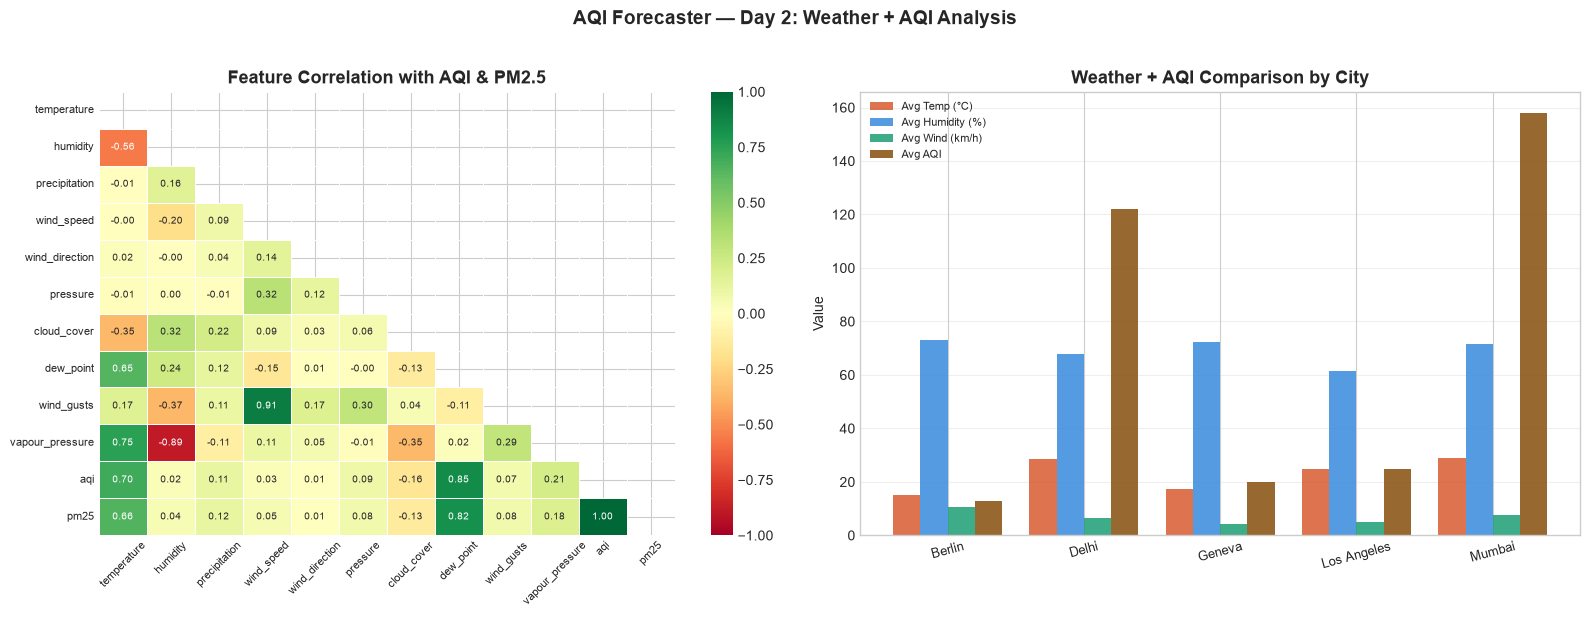

✓ Plot saved: ../results/day2_correlation.png

--- TOP CORRELATIONS WITH AQI ---
  pm25                : +0.995  ↑ increases AQI
  dew_point           : +0.851  ↑ increases AQI
  temperature         : +0.697  ↑ increases AQI
  vapour_pressure     : +0.214  ↑ increases AQI
  cloud_cover         : -0.158  ↓ decreases AQI
  precipitation       : +0.114  ↑ increases AQI
  pressure            : +0.087  ↑ increases AQI
  wind_gusts          : +0.068  ↑ increases AQI
  wind_speed          : +0.028  ↑ increases AQI
  humidity            : +0.024  ↑ increases AQI
  wind_direction      : +0.007  ↑ increases AQI
✓ 3720 hourly weather records collected
✓ 55 features engineered
✓ Correlation analysis done
✓ Data saved to data/processed/merged_dataset.csv


In [ ]:
# ============================================
# Visualization
# Correlation Heatmap + City Comparison
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Plot 1: Correlation Heatmap ---
key_cols = [
    'temperature', 'humidity', 'precipitation',
    'wind_speed', 'wind_direction', 'pressure',
    'cloud_cover', 'dew_point', 'wind_gusts',
    'vapour_pressure', 'aqi', 'pm25'
]

df_corr = df_merged[key_cols].dropna()
corr_matrix = df_corr.corr()

# Plot heatmap
mask = np.zeros_like(corr_matrix, dtype=bool)
mask[np.triu_indices_from(mask)] = True

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    center=0,
    vmin=-1, vmax=1,
    ax=axes[0],
    linewidths=0.5,
    annot_kws={'size': 7}
)
axes[0].set_title('Feature Correlation with AQI & PM2.5',
                   fontsize=13, fontweight='bold')
axes[0].tick_params(axis='x', rotation=45, labelsize=8)
axes[0].tick_params(axis='y', rotation=0,  labelsize=8)

# --- Plot 2: Weather comparison by city ---
city_weather = df_merged.groupby('city').agg({
    'temperature':   'mean',
    'humidity':      'mean',
    'wind_speed':    'mean',
    'precipitation': 'sum',
    'aqi':           'mean',
}).round(1)

x = np.arange(len(city_weather))
width = 0.2

bars1 = axes[1].bar(x - width*1.5, city_weather['temperature'],
                     width, label='Avg Temp (°C)',  color='#D85A30', alpha=0.85)
bars2 = axes[1].bar(x - width*0.5, city_weather['humidity'],
                     width, label='Avg Humidity (%)', color='#378ADD', alpha=0.85)
bars3 = axes[1].bar(x + width*0.5, city_weather['wind_speed'],
                     width, label='Avg Wind (km/h)', color='#1D9E75', alpha=0.85)
bars4 = axes[1].bar(x + width*1.5, city_weather['aqi'],
                     width, label='Avg AQI',         color='#854F0B', alpha=0.85)

axes[1].set_xticks(x)
axes[1].set_xticklabels(city_weather.index, rotation=15, fontsize=9)
axes[1].set_title('Weather + AQI Comparison by City',
                   fontsize=13, fontweight='bold')
axes[1].legend(fontsize=8)
axes[1].set_ylabel('Value', fontsize=10)
axes[1].grid(True, alpha=0.3, axis='y')

plt.suptitle('AQI Forecaster —  Weather + AQI Analysis',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()

# Save
plot_path = '../results/correlation.png'
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✓ Plot saved: {plot_path}")
print("\n--- TOP CORRELATIONS WITH AQI ---")
aqi_corr = corr_matrix['aqi'].drop('aqi').sort_values(key=abs, ascending=False)
for feature, val in aqi_corr.items():
    direction = "↑ increases AQI" if val > 0 else "↓ decreases AQI"
    print(f"  {feature:20s}: {val:+.3f}  {direction}")

print("=" * 45)
print(f"✓ 3720 hourly weather records collected")
print(f"✓ 55 features engineered")
print(f"✓ Correlation analysis done")
print(f"✓ Data saved to data/processed/merged_dataset.csv")
print("=" * 45)
